# 85. 실제 예보로 돌린 백테스트: 전날 17시 단기예보 → 경보·우선순위

80번은 관측 날씨를 넣고 순위를 평가했다(완전 예보). 여기서는 기상청 API허브 동네예보 격자 자료(`09b_kma_forecast.py`, 전날 17시 발표, 강남·춘천 격자점)를 넣는다.
1. 예보 정확도: 우리 이벤트 정의(영업시간 비 10mm+, 폭염일)에 대한 적중률·헛경보율
2. 예보 기반 경보·우선순위: 같은 달-제외 교차검증으로 예보 날씨로 점수를 내고, 실제 손실과 비교한다(관측 날씨 점수와 나란히)
3. 경보 운영 지표: 예보 경보가 잡은 손실 비중, 헛경보 일수, 날짜별 예상 손실 합과 실제 손실 합의 상관

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

sys.path.insert(0, str(Path.cwd()))
from common import FIG, TAB, REGIONS, REGION_NAME, FACE_GROUPS, load
from analysis import RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, EVENT_COLOR, exclusion_days, deviation, finish
import models as M
import priority as P

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
cal = load("calendar"); EXCL = exclusion_days(cal)
panel = load("model_panel_day"); tb_panel = load("model_panel_tb")
best_path = TAB / "t_best_params.json"
best = json.load(open(best_path, encoding="utf-8")) if best_path.exists() else {}
CLS_PARAMS = {**M.CLS_PARAMS, **best.get("cls", {}), "subsample_freq": 1, "random_state": 42, "verbose": -1}
CLS_FEATS = M.CLS_FEAT_EXP if best.get("cls_feat") == "exp" else M.CLS_FEAT
d = M.load_daily()
ev = M.load_events(d); ev["month"] = ev.date.dt.month
fc = load("kma_forecast_daily"); fc["date"] = pd.to_datetime(fc["date"])
obs = load("weather_daily")
print(f"예보 {fc.date.min().date()}~{fc.date.max().date()} {len(fc)}행(지역·일), 예보 영업시간 비 10mm+ 일수:", fc.groupby("region").fc_rain_biz10.sum().to_dict())

예보 2025-07-01~2025-12-31 368행(지역·일), 예보 영업시간 비 10mm+ 일수: {'chuncheon': 30, 'gangnam': 23}


C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:37: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = np.log1p(df.pivot_table(index="date", columns=keys, values=value, aggfunc="sum")).reindex(DATES)


## 1. 예보 정확도: 우리 이벤트 정의 기준

In [2]:
OBS = ["rn_biz", "rn_sum", "rain_biz10", "rain_biz20", "ta_max_off", "heat_day", "rn_biz_hours", "heat_streak", "night_min", "tropical", "rain_dawn_only"]
m = fc.merge(obs[["region", "date"] + OBS], on=["region", "date"], how="inner")
def skill(o, f):
    o, f = o.astype(bool).values, f.astype(bool).values
    h, miss, fa, cn = int((o & f).sum()), int((o & ~f).sum()), int((~o & f).sum()), int((~o & ~f).sum())
    return {"관측 일수": h + miss, "예보 일수": h + fa, "적중": h, "놓침": miss, "헛경보": fa,
            "적중률 POD": h / (h + miss) if h + miss else np.nan, "헛경보율 FAR": fa / (h + fa) if h + fa else np.nan, "CSI": h / (h + miss + fa) if h + miss + fa else np.nan}
DEFS = [("영업시간 비 10mm+ (예보 강수량 10mm+)", "rain_biz10", lambda x: x.fc_rain_biz10), ("영업시간 비 10mm+ (예보 강수량 5mm+)", "rain_biz10", lambda x: x.fc_rn_biz >= 5),
        ("영업시간 비 10mm+ (예보 강수확률 60%+)", "rain_biz10", lambda x: x.fc_pop60), ("영업시간 비 10mm+ (강수확률 60%+ 또는 강수량 5mm+)", "rain_biz10", lambda x: (x.fc_pop60 == 1) | (x.fc_rn_biz >= 5)),
        ("영업시간 비 20mm+ (예보 20mm+)", "rain_biz20", lambda x: x.fc_rain_biz20), ("폭염일 33℃ (예보 최고기온 33℃+)", "heat_day", lambda x: x.fc_heat_day),
        ("폭염일 33℃ (예보 32℃+)", "heat_day", lambda x: x.fc_tmax >= 32)]
rows = []
for region in REGIONS + ["both"]:
    mm = m if region == "both" else m[m.region == region]
    for name, oc, f in DEFS:
        rows.append({"지역": REGION_NAME.get(region, "합계"), "정의": name, **skill(mm[oc], f(mm))})
sk = pd.DataFrame(rows)
sk.round(3).to_csv(TAB / "f_forecast_skill.csv", index=False, encoding="utf-8-sig")
wet = m[(m.rain_biz10 == 1) | (m.fc_rain_biz10 == 1)]
amt = wet.groupby("region").apply(lambda g: pd.Series({"일수": len(g), "예보−관측 평균(mm)": (g.fc_rn_biz - g.rn_biz).mean(), "절대오차 평균(mm)": (g.fc_rn_biz - g.rn_biz).abs().mean(),
                                                     "상관": np.corrcoef(g.fc_rn_biz, g.rn_biz)[0, 1]}), include_groups=False)
tmx = m.groupby("region").apply(lambda g: pd.Series({"최고기온 절대오차(℃)": (g.fc_tmax - g.ta_max_off).abs().mean(), "편향(℃)": (g.fc_tmax - g.ta_max_off).mean()}), include_groups=False)
amt.round(2).to_csv(TAB / "f_forecast_rain_amount.csv", encoding="utf-8-sig")
print("영업시간 강수량(관측 또는 예보 10mm+ 날):"); print(amt.round(2)); print(tmx.round(2))
sk[sk.지역 == "합계"].round(2)

영업시간 강수량(관측 또는 예보 10mm+ 날):
             일수  예보−관측 평균(mm)  절대오차 평균(mm)    상관
region                                          
chuncheon  38.0          2.66        19.83  0.19
gangnam    31.0          5.02        23.92 -0.26
           최고기온 절대오차(℃)  편향(℃)
region                        
chuncheon          1.43  -0.17
gangnam            1.17   0.42


,지역,정의,관측 일수,예보 일수,적중,놓침,헛경보,적중률 POD,헛경보율 FAR,CSI
14,합계,영업시간 비 10mm+ (예보 강수량 10mm+),38,53,22,16,31,0.58,0.58,0.32
15,합계,영업시간 비 10mm+ (예보 강수량 5mm+),38,68,28,10,40,0.74,0.59,0.36
16,합계,영업시간 비 10mm+ (예보 강수확률 60%+),38,115,38,0,77,1.00,0.67,0.33
17,합계,영업시간 비 10mm+ (강수확률 60%+ 또는 강수량 5mm+),38,118,38,0,80,1.00,0.68,0.32
18,합계,영업시간 비 20mm+ (예보 20mm+),20,31,6,14,25,0.30,0.81,0.13
19,합계,폭염일 33℃ (예보 최고기온 33℃+),55,64,44,11,20,0.80,0.31,0.59
20,합계,폭염일 33℃ (예보 32℃+),55,98,50,5,48,0.91,0.49,0.49


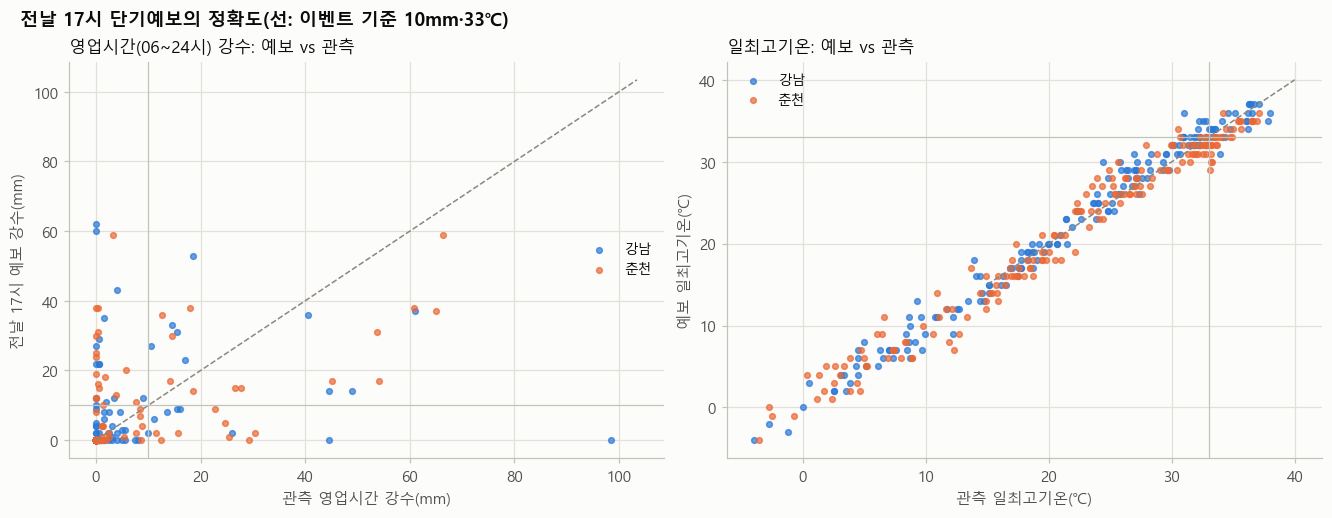

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
ax = axes[0]
for r in REGIONS:
    g = m[m.region == r]
    ax.scatter(g.rn_biz, g.fc_rn_biz, s=14, color=REGION_COLOR[r], alpha=0.7, label=REGION_NAME[r])
lim = max(m.rn_biz.max(), m.fc_rn_biz.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--"); ax.axvline(10, color=AXIS, lw=0.8); ax.axhline(10, color=AXIS, lw=0.8)
ax.set_xlabel("관측 영업시간 강수(mm)"); ax.set_ylabel("전날 17시 예보 강수(mm)"); ax.set_title("영업시간(06~24시) 강수: 예보 vs 관측"); ax.legend(frameon=False)
ax = axes[1]
for r in REGIONS:
    g = m[m.region == r]
    ax.scatter(g.ta_max_off, g.fc_tmax, s=14, color=REGION_COLOR[r], alpha=0.7, label=REGION_NAME[r])
ax.plot([15, 40], [15, 40], color=MUTED, lw=1, ls="--"); ax.axvline(33, color=AXIS, lw=0.8); ax.axhline(33, color=AXIS, lw=0.8)
ax.set_xlabel("관측 일최고기온(℃)"); ax.set_ylabel("예보 일최고기온(℃)"); ax.set_title("일최고기온: 예보 vs 관측"); ax.legend(frameon=False)
finish(fig, FIG, "f01_forecast_skill", "전날 17시 단기예보의 정확도(선: 이벤트 기준 10mm·33℃)")
plt.show()

## 2. 예보 날씨로 점수를 내면: 경보와 우선순위

80번과 같은 달-제외 교차검증. 시험 달의 모든 날(대면 업종)에 대해 분류기와 β 손실을 **예보 날씨**로 계산한다. 예보에서 못 받는 입력은 전날까지 아는 값으로 채운다: 체감온도는 예보 최고기온, 밤 최저기온은 예보 최저기온, 습도는 학습 기간 지역 평균, 더위 연속일수는 전날 관측값+1, 전날 강수는 관측값.

In [4]:
DEV_LO, DEV_HI = np.nanquantile(ev.dev.values, [0.02, 0.98])
face = d[d.face == 1].copy()
devall = deviation(face, ["region", "industry"], excl=EXCL)
devall["region"], devall["industry"] = devall.region.astype(str), devall.industry.astype(str)
fcw = fc.set_index(["region", "date"])
obsw = obs.set_index(["region", "date"])

def with_forecast(rows, hm_by_region):
    rows = rows.copy()
    idx = pd.MultiIndex.from_arrays([rows.region.astype(str).values, rows.date.values])
    f = fcw.reindex(idx)
    prev = obsw.reindex(pd.MultiIndex.from_arrays([rows.region.astype(str).values, (rows.date - pd.Timedelta(days=1)).values]))
    ok = f.fc_tmax.notna().values & f.fc_rn_06_11.notna().values
    rn06, rn12, rn18 = (np.nan_to_num(f[c].values) for c in ["fc_rn_06_11", "fc_rn_12_17", "fc_rn_18_23"])
    rows["w_rn_06"], rows["w_rn_12"], rows["w_rn_18"] = rn06, rn12, rn18
    rows["w_rn_biz"] = rn06 + rn12 + rn18
    rows["w_rn_sum"] = rows.w_rn_biz.values + np.nan_to_num(f.fc_rn_dawn.values)
    rows["w_rn_biz_hours"] = np.nan_to_num(f.fc_rn_hours_biz.values)
    rows["w_rain_biz10"] = (rows.w_rn_biz >= 10).astype(int)
    tmax, tmin = f.fc_tmax.values, f.fc_tmin.values
    rows["w_ta_max_off"], rows["w_feels_max"], rows["w_night_min"] = tmax, tmax, tmin
    rows["w_heat_day"] = (tmax >= 33).astype(int)
    rows["w_tropical"] = (tmin >= 25).astype(int)
    rows["w_hm_mean"] = rows.region.astype(str).map(hm_by_region).values
    rows["w_heat_streak"] = np.where(tmax >= 33, np.nan_to_num(prev.heat_streak.values) + 1, 0)
    rows = M.add_exposure_features(rows)
    return rows[ok]

def realized(sc):
    sc = sc.merge(devall, on=["region", "industry", "date"], how="inner")
    sc["w_rn_biz"] = sc.w_rn_06 + sc.w_rn_12 + sc.w_rn_18
    sc["dev_w"] = sc.dev.clip(DEV_LO, DEV_HI)
    sc["realized_net"] = sc.base_sales * (1 - np.exp(sc.dev_w))
    sc["realized"] = sc.realized_net.clip(lower=0)
    return sc

parts = {"예보": [], "관측": []}
for m_ in sorted(ev.month.unique()):
    tr_ev = ev[ev.month != m_]
    model = P.PriorityModel.fit(tr_ev, panel[panel.date.dt.month != m_], tb_panel[tb_panel.date.dt.month != m_], EXCL, CLS_PARAMS, CLS_FEATS)
    hm_by_region = tr_ev.groupby(tr_ev.region.astype(str)).w_hm_mean.mean().to_dict()
    te = face[face.date.dt.month == m_]
    tf = with_forecast(te, hm_by_region)
    if len(tf):  # 예보가 없는 달(수집 전)은 건너뛴다
        parts["예보"].append(realized(model.score(tf)))
    parts["관측"].append(realized(model.score(te)))
SC = {k: pd.concat(v, ignore_index=True) for k, v in parts.items()}
for k, v in SC.items():
    assert not v.duplicated(["region", "industry", "date"]).any()
    v["region"] = v.region.astype(str)
SB = {k: v[v.small_biz == 1].copy() for k, v in SC.items()}
obs_flag = obs.set_index(["region", "date"])[["rain_biz10", "rn_biz"]]
for k in SB:
    SB[k] = SB[k].join(obs_flag.rename(columns={"rain_biz10": "obs_rain_biz10", "rn_biz": "obs_rn_biz"}), on=["region", "date"])
print({k: f"{len(v):,}행, 날짜 {v.date.nunique()}일" for k, v in SB.items()})

C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:37: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = np.log1p(df.pivot_table(index="date", columns=keys, values=value, aggfunc="sum")).reindex(DATES)


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


{'예보': '9,096행, 날짜 111일', '관측': '9,096행, 날짜 111일'}


### 관측 호우일에서의 순위: 예보 점수 vs 관측 점수 vs 규모순

In [5]:
METH = [("알고리즘(예상 손실)", "priority"), ("사후 기대 β", "priority_post"), ("p × 예상 손실", "priority_p"), ("규모순", "base_sales"), ("확률순", "p_alert")]
rows = []
rain_days = SB["관측"][SB["관측"].obs_rain_biz10 == 1][["region", "date"]].drop_duplicates()
for (r, dt), _ in rain_days.groupby(["region", "date"]):
    g_o = SB["관측"][(SB["관측"].region == r) & (SB["관측"].date == dt)].set_index("industry")
    g_f = SB["예보"][(SB["예보"].region == r) & (SB["예보"].date == dt)].set_index("industry")
    if len(g_o) < 15 or g_o.realized.sum() <= 0 or len(g_f) == 0:
        continue
    tot = g_o.realized.sum()
    rec = {"region": r, "date": dt, "n": len(g_o), "실제 손실 합(백만)": tot / 1e6, "예보 호우": int(g_f.w_rain_biz10.iloc[0]), "예보 강수(mm)": float(g_f.w_rn_biz.iloc[0]), "관측 강수(mm)": float(g_o.obs_rn_biz.iloc[0])}
    for src, g in [("예보", g_f), ("관측", g_o)]:
        for name, col in METH:
            top = g[col].fillna(0).nlargest(10).index
            rec[f"{src}·{name} 상위10 손실 포함(%)"] = g_o.loc[g_o.index.intersection(top), "realized"].sum() / tot * 100
            rec[f"{src}·{name} 상관"] = spearmanr(g[col].fillna(0).reindex(g_o.index).fillna(0), g_o.realized_net).correlation
    rec["무작위 상위10 손실 포함(%)"] = 10 / len(g_o) * 100
    rows.append(rec)
bt = pd.DataFrame(rows)
bt.round(3).to_csv(TAB / "f_backtest_daily.csv", index=False, encoding="utf-8-sig")
summ = pd.DataFrame({f"{src}·{name}": {"상위10 손실 포함(%)": bt[f"{src}·{name} 상위10 손실 포함(%)"].mean(), "평균 순위 상관": bt[f"{src}·{name} 상관"].mean()}
                     for src in ["예보", "관측"] for name, _ in METH}).T
summ.loc["무작위"] = [bt["무작위 상위10 손실 포함(%)"].mean(), 0.0]
summ.round(3).to_csv(TAB / "f_backtest.csv", encoding="utf-8-sig")
print(f"관측 호우일 {len(bt)}일(그중 전날 예보도 호우 {int(bt['예보 호우'].sum())}일)")
summ.round(2)

C:\Users\nk233\AppData\Local\Temp\ipykernel_2708\947122189.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rec[f"{src}·{name} 상관"] = spearmanr(g[col].fillna(0).reindex(g_o.index).fillna(0), g_o.realized_net).correlation
C:\Users\nk233\AppData\Local\Temp\ipykernel_2708\947122189.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rec[f"{src}·{name} 상관"] = spearmanr(g[col].fillna(0).reindex(g_o.index).fillna(0), g_o.realized_net).correlation
C:\Users\nk233\AppData\Local\Temp\ipykernel_2708\947122189.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rec[f"{src}·{name} 상관"] = spearmanr(g[col].fillna(0).reindex(g_o.index).fillna(0), g_o.realized_net).correlation


관측 호우일 32일(그중 전날 예보도 호우 20일)


,상위10 손실 포함(%),평균 순위 상관
예보·알고리즘(예상 손실),55.42,0.38
예보·사후 기대 β,55.74,0.40
예보·p × 예상 손실,57.16,0.37
예보·규모순,58.27,0.39
예보·확률순,24.99,-0.04
관측·알고리즘(예상 손실),58.83,0.41
관측·사후 기대 β,58.76,0.41
관측·p × 예상 손실,58.13,0.40
관측·규모순,58.27,0.39
관측·확률순,27.21,0.06


### 경보 운영: 예보 경보가 잡은 손실, 헛경보, 날짜별 예상 손실 합과 실제 손실 합

In [6]:
day_f = SB["예보"].groupby(["region", "date"]).agg(exp_loss=("expected_loss", "sum"), p_mean=("p_alert", "mean"), n_alert=("p_alert", lambda s: int((s >= 0.5).sum())),
                                                   fc_rain=("w_rain_biz10", "first"), fc_rn=("w_rn_biz", "first"), realized=("realized", "sum"), realized_net=("realized_net", "sum"),
                                                   obs_rain=("obs_rain_biz10", "first"), obs_rn=("obs_rn_biz", "first")).reset_index()
day_o = SB["관측"].groupby(["region", "date"]).agg(exp_loss_obs=("expected_loss", "sum")).reset_index()
day = day_f.merge(day_o, on=["region", "date"], how="left")
day["지역"] = day.region.map(REGION_NAME)
rows = []
for r, g in day.groupby("지역"):
    rain = g[g.obs_rain == 1]
    for name, flag in [("예보 강수량 10mm+", g.fc_rain == 1), ("예보 강수량 5mm+", g.fc_rn >= 5), ("예보 예상 손실 ≥ 호우일 중앙값", g.exp_loss >= rain.exp_loss.median() if len(rain) else g.exp_loss > np.inf)]:
        a = g[flag]
        rows.append({"지역": r, "경보 기준": name, "경보 일수": len(a), "그중 실제 호우일": int(a.obs_rain.sum()), "헛경보(실제 비 없음)": int((a.obs_rain == 0).sum()),
                     "놓친 호우일": int((rain.index.isin(a.index) == False).sum()), "경보일이 포함한 호우일 손실 비중(%)": rain.loc[rain.index.isin(a.index), "realized"].sum() / rain.realized.sum() * 100 if len(rain) else np.nan,
                     "헛경보일 평균 순손실(백만)": a.loc[a.obs_rain == 0, "realized_net"].mean() / 1e6 if (a.obs_rain == 0).any() else np.nan,
                     "호우일 평균 순손실(백만)": rain.realized_net.mean() / 1e6})
alerts = pd.DataFrame(rows)
alerts.round(2).to_csv(TAB / "f_alert_operation.csv", index=False, encoding="utf-8-sig")
corr = day.groupby("지역").apply(lambda g: pd.Series({"예보 예상 손실 vs 실제(상관)": np.corrcoef(g.exp_loss, g.realized_net)[0, 1], "관측 예상 손실 vs 실제(상관)": np.corrcoef(g.exp_loss_obs.fillna(0), g.realized_net)[0, 1],
                                                     "호우일만: 예보 vs 실제": np.corrcoef(g[g.obs_rain == 1].exp_loss, g[g.obs_rain == 1].realized_net)[0, 1] if (g.obs_rain == 1).sum() > 3 else np.nan}), include_groups=False)
corr.round(3).to_csv(TAB / "f_daily_corr.csv", encoding="utf-8-sig")
day.round(2).to_csv(TAB / "f_daily_expected_vs_realized.csv", index=False, encoding="utf-8-sig")
print(corr.round(2)); alerts.round(1)

    예보 예상 손실 vs 실제(상관)  관측 예상 손실 vs 실제(상관)  호우일만: 예보 vs 실제
지역                                                        
강남                0.19                0.28             0.1
춘천                0.32                0.46            -0.1


,지역,경보 기준,경보 일수,그중 실제 호우일,헛경보(실제 비 없음),놓친 호우일,경보일이 포함한 호우일 손실 비중(%),헛경보일 평균 순손실(백만),호우일 평균 순손실(백만)
0,강남,예보 강수량 10mm+,20,8,12,6,61.4,-556.2,498.2
1,강남,예보 강수량 5mm+,29,12,17,2,80.6,-485.6,498.2
2,강남,예보 예상 손실 ≥ 호우일 중앙값,17,7,10,7,50.4,-564.1,498.2
3,춘천,예보 강수량 10mm+,27,12,15,6,63.9,-53.3,355.6
4,춘천,예보 강수량 5mm+,30,13,17,5,66.1,-33.7,355.6
5,춘천,예보 예상 손실 ≥ 호우일 중앙값,20,9,11,9,48.8,-134.4,355.6


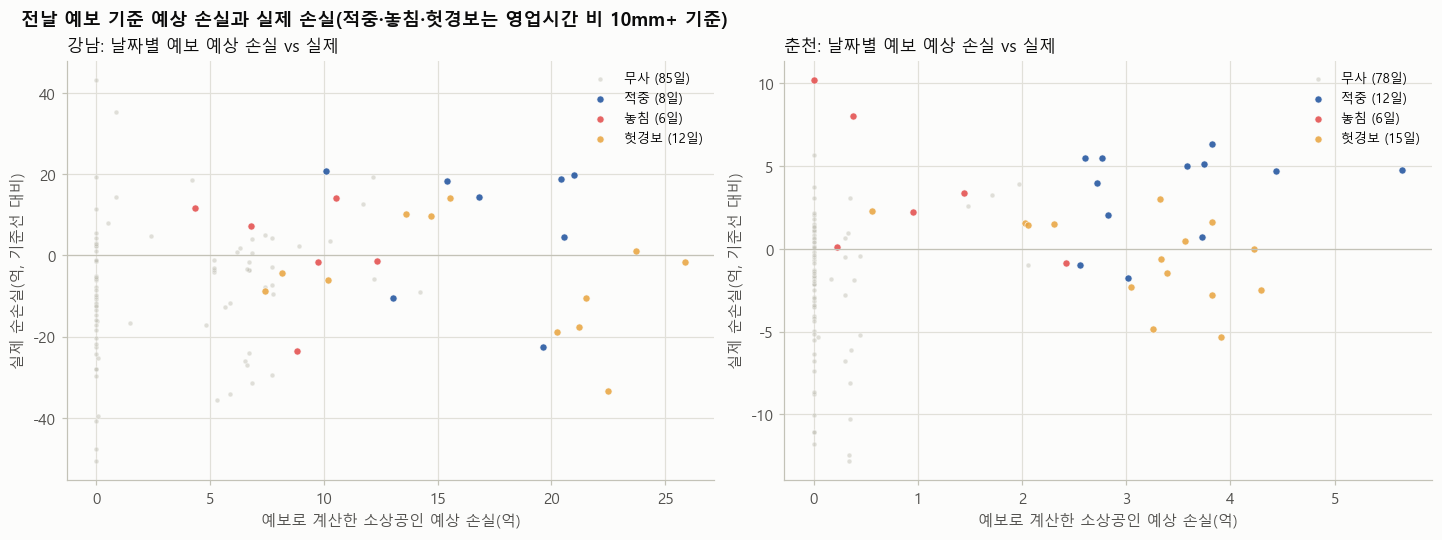

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, r in zip(axes, REGIONS):
    g = day[day.region == r]
    cat = np.select([(g.obs_rain == 1) & (g.fc_rain == 1), (g.obs_rain == 1) & (g.fc_rain == 0), (g.obs_rain == 0) & (g.fc_rain == 1)], ["적중", "놓침", "헛경보"], "무사")
    colors = {"적중": "#1b4f9c", "놓침": "#e34948", "헛경보": "#e8a33d", "무사": "#c3c2b7"}
    for k in ["무사", "적중", "놓침", "헛경보"]:
        s = g[cat == k]
        ax.scatter(s.exp_loss / 1e8, s.realized_net / 1e8, s=22 if k != "무사" else 10, color=colors[k], alpha=0.85 if k != "무사" else 0.5, label=f"{k} ({len(s)}일)", edgecolors=SURFACE, linewidths=0.5)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xlabel("예보로 계산한 소상공인 예상 손실(억)"); ax.set_ylabel("실제 순손실(억, 기준선 대비)"); ax.set_title(f"{REGION_NAME[r]}: 날짜별 예보 예상 손실 vs 실제"); ax.legend(frameon=False, fontsize=8.5)
finish(fig, FIG, "f02_forecast_daily", "전날 예보 기준 예상 손실과 실제 손실(적중·놓침·헛경보는 영업시간 비 10mm+ 기준)")
plt.show()

## 요약

In [8]:
sk_all = sk[sk.지역 == "합계"].set_index("정의")
summary = pd.DataFrame({"호우일 예보 적중률/헛경보율(10mm 기준)": [f"{sk_all.loc['영업시간 비 10mm+ (예보 강수량 10mm+)', '적중률 POD']:.2f} / {sk_all.loc['영업시간 비 10mm+ (예보 강수량 10mm+)', '헛경보율 FAR']:.2f}"],
                        "호우일 예보 적중률/헛경보율(5mm 기준)": [f"{sk_all.loc['영업시간 비 10mm+ (예보 강수량 5mm+)', '적중률 POD']:.2f} / {sk_all.loc['영업시간 비 10mm+ (예보 강수량 5mm+)', '헛경보율 FAR']:.2f}"],
                        "폭염일 예보 적중률/헛경보율": [f"{sk_all.loc['폭염일 33℃ (예보 최고기온 33℃+)', '적중률 POD']:.2f} / {sk_all.loc['폭염일 33℃ (예보 최고기온 33℃+)', '헛경보율 FAR']:.2f}"],
                        "상위10 손실 포함(예보/관측/규모순, %)": [f"{summ.loc['예보·알고리즘(예상 손실)', '상위10 손실 포함(%)']:.0f} / {summ.loc['관측·알고리즘(예상 손실)', '상위10 손실 포함(%)']:.0f} / {summ.loc['관측·규모순', '상위10 손실 포함(%)']:.0f}"],
                        "날짜별 예상 손실-실제 상관(예보/관측, 강남·춘천)": [" | ".join(f"{i}: {row['예보 예상 손실 vs 실제(상관)']:.2f}/{row['관측 예상 손실 vs 실제(상관)']:.2f}" for i, row in corr.iterrows())]}).T
summary.columns = ["값"]
summary.to_csv(TAB / "f_summary.csv", encoding="utf-8-sig")
summary

,값
호우일 예보 적중률/헛경보율(10mm 기준),0.58 / 0.58
호우일 예보 적중률/헛경보율(5mm 기준),0.74 / 0.59
폭염일 예보 적중률/헛경보율,0.80 / 0.31
"상위10 손실 포함(예보/관측/규모순, %)",55 / 59 / 58
"날짜별 예상 손실-실제 상관(예보/관측, 강남·춘천)",강남: 0.19/0.28 | 춘천: 0.32/0.46
